In [8]:
# imports + settings 
import kagglehub
import os

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder

plt.rcParams.update({
    "figure.facecolor":  "#ffffff",
    "axes.facecolor":    "#f9f9f9",
    "axes.spines.top":   False,
    "axes.spines.right": False,
    "axes.grid":         True,
    "grid.color":        "#e5e5e5",
    "grid.linewidth":    0.6,
    "font.family":       "Helvetica",
    "font.size":         11,
})

BLUE    =   "#151B54"
RED     =   "#BF2C34"
ORANGE  =   "#FC6238"
GREEN   =   "#009D52"
PURPLE  =   "#4c00b0"

# download latest version
path = kagglehub.dataset_download("mohankrishnathalla/credit-card-fraud-detection-dataset-2026")
file_path = os.path.join(path, "credit_card_fraud_detection_2026.csv")
fraud_df = pd.read_csv(file_path)

# make extra temporal features
fraud_df["transaction_datetime"] = pd.to_datetime(df["transaction_datetime"])
fraud_df["transaction_month"] = fraud_df["transaction_datetime"].dt.month
fraud_df["transaction_date"] = fraud_df["transaction_datetime"].dt.date

# initial info
print(f"shape: {fraud_df}")
print(f"missing values: {fraud_df.isnull().sum().sum()}")
print(f"date range: {fraud_df.transaction_datetime.min()} - {df.transaction_datetime.max()}")
print(f"unique customers: {fraud_df.customer_id.nunique()}")
print(f"unique merchants: {fraud_df.merchant_id.nunique()}")

shape:       transaction_id   customer_id       card_id   merchant_id  \
0       TXN-00000001  CUS-00006042  CRD-00006042  MER-00002507   
1       TXN-00000002  CUS-00005262  CRD-00005262  MER-00000189   
2       TXN-00000003  CUS-00005901  CRD-00005901  MER-00002054   
3       TXN-00000004  CUS-00006958  CRD-00006958  MER-00000310   
4       TXN-00000005  CUS-00003543  CRD-00003543  MER-00001197   
...              ...           ...           ...           ...   
99995   TXN-00099996  CUS-00006390  CRD-00006390  MER-00000996   
99996   TXN-00099997  CUS-00006126  CRD-00006126  MER-00001056   
99997   TXN-00099998  CUS-00004651  CRD-00004651  MER-00002493   
99998   TXN-00099999  CUS-00007845  CRD-00007845  MER-00002563   
99999   TXN-00100000  CUS-00002752  CRD-00002752  MER-00001618   

      transaction_datetime  transaction_amount         merchant_category  \
0      2026-01-01 02:28:51               37.36     Healthcare & Pharmacy   
1      2026-01-01 03:15:18               50.04  

### What to look into ###
- class imbalance
- temporal features
- merchant features
- transaction features

In [9]:
fraud_df.dtypes

transaction_id                            str
customer_id                               str
card_id                                   str
merchant_id                               str
transaction_datetime           datetime64[us]
transaction_amount                    float64
merchant_category                         str
merchant_country                          str
transaction_hour                        int64
transaction_day_of_week                   str
card_present                            int64
customer_age                            int64
customer_gender                           str
customer_state                            str
account_age_days                        int64
credit_limit                          float64
credit_score                            int64
num_cards_held                          int64
transactions_last_1h                    int64
transactions_last_24h                   int64
transactions_last_7d                    int64
amount_last_1h                    

### Exploratory Data Analysis (EDA) ###

In [10]:
pd.set_option("display.max_columns", None)
fraud_df.describe().round(2)

,transaction_datetime,transaction_amount,transaction_hour,card_present,customer_age,account_age_days,credit_limit,credit_score,num_cards_held,transactions_last_1h,transactions_last_24h,transactions_last_7d,amount_last_1h,amount_last_24h,days_since_last_transaction,distance_from_home_km,distance_from_last_tx_km,international_transaction,high_risk_country,amount_vs_avg_ratio,used_chip,used_pin,is_weekend,avg_transaction_amount_30d,std_transaction_amount_30d,num_declined_last_30d,num_chargebacks_ever,is_fraud,fraud_amount_lost,transaction_month
count,100000,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00
mean,2026-07-02 11:04:30.563410,126.87,14.39,0.36,42.22,785.45,10083.18,682.33,2.20,0.78,2.95,8.84,96.89,367.71,3.50,4316.75,939.44,0.55,0.05,1.96,0.31,0.18,0.28,124.40,68.46,0.51,0.37,0.02,2.80,6.52
min,2026-01-01 02:28:51,0.50,0.00,0.00,18.00,1.00,500.00,328.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,5.38,2.46,0.00,0.00,0.00,0.00,1.00
25%,2026-04-01 08:31:50.250000,21.28,11.00,0.00,32.00,233.00,5000.00,620.00,1.00,0.00,1.00,4.00,0.00,77.63,1.00,20.60,5.20,0.00,0.00,0.21,0.00,0.00,0.00,52.46,26.88,0.00,0.00,0.00,0.00,4.00
50%,2026-07-02 17:46:21.500000,52.26,14.00,0.00,42.00,554.00,8500.00,683.00,2.00,0.00,2.00,7.00,0.00,197.70,2.40,1949.95,13.30,1.00,0.00,0.58,0.00,0.00,0.00,89.37,48.17,0.00,0.00,0.00,0.00,7.00
75%,2026-10-02 08:26:00.500000,129.72,19.00,1.00,52.00,1103.00,13650.00,748.00,3.00,1.00,4.00,12.00,100.01,445.41,4.80,8482.35,31.90,1.00,0.00,1.66,1.00,0.00,1.00,155.08,85.42,1.00,0.00,0.00,0.00,10.00
max,2026-12-31 23:45:47,15000.00,23.00,1.00,85.00,3650.00,36670.00,850.00,5.00,8.00,18.00,42.00,11421.39,15161.52,47.30,14999.80,11999.60,1.00,1.00,686.32,1.00,1.00,1.00,2000.00,1334.92,5.00,4.00,1.00,4482.16,12.00
std,NaN,276.18,5.02,0.48,14.25,747.49,6510.65,92.12,1.16,1.35,2.38,6.36,252.18,551.65,3.52,4946.79,2551.11,0.50,0.22,6.37,0.46,0.39,0.45,119.71,70.83,1.01,0.79,0.14,43.67,3.46


In [11]:
def _null_counts(df: pd.DataFrame):
    nulls = {}
    for col in df.columns:
        nulls[col] = df[col].isna().sum()
    nulls_df  = pd.DataFrame(list(nulls.items()), columns=["column", "nulls"])
    # display cols with nulls
    nulls_df = nulls_df[nulls_df["nulls"] > 0].reset_index(drop=True)
    return nulls_df

nulls_df = _null_counts(fraud_df)
display(nulls_df)

,column,nulls
0,browser,41709


In [12]:
# cat distributions
cat_cols = ["merchant_category", "merchant_country", "customer_gender", "customer_state", "transaction_channel", "device_type", "browser", "email_domain", "transaction_day_of_week"]
for col in cat_cols:
    print(fraud_df[col].value_counts().to_string())
    print()

merchant_category
Online Retail                13417
Restaurant & Dining          12736
Grocery & Supermarket        12137
Gas Station                  10885
Healthcare & Pharmacy         7903
Electronics & Technology      6934
Travel & Airlines             6612
Hotel & Lodging               6360
Clothing & Apparel            6324
Entertainment & Streaming     5848
Auto & Transportation         3974
Home Improvement              3824
Education                     1137
Utilities & Telecom           1036
Financial Services             873

merchant_country
USA             44515
UK               8349
Canada           7238
Germany          5651
Australia        5423
France           4521
Italy            3344
Netherlands      3039
Spain            2849
Brazil           2354
India            2175
Mexico           1921
China            1682
Nigeria          1261
South Africa     1140
Russia           1046
Romania           943
UAE               940
Japan             821
South Korea       788

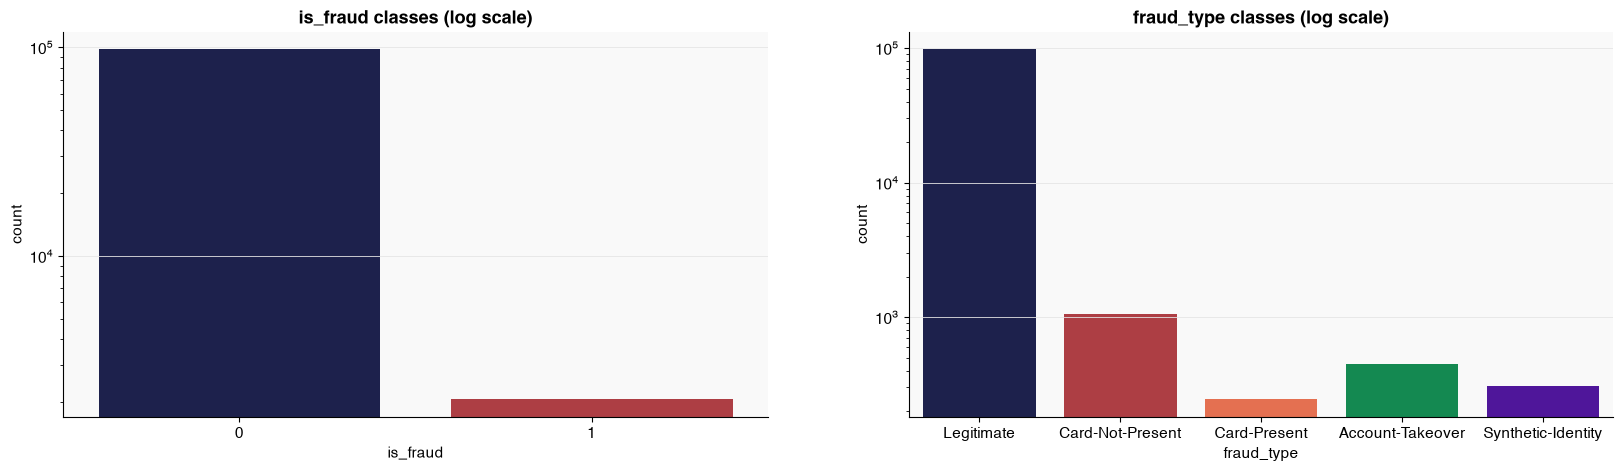

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(20, 5))
total = len(fraud_df)

# is_fraud class distribution
sns.countplot(
    data=fraud_df,
    x="is_fraud",
    hue="is_fraud",
    palette=[BLUE, RED],
    ax=ax[0], 
    legend=False,
)
ax[0].set_yscale("log", nonpositive="clip")
ax[0].set_title("is_fraud classes (log scale)", fontweight="bold")

# fraud_type class distribution 
sns.countplot(
    data=fraud_df,
    x="fraud_type",
    hue="fraud_type",
    palette=[BLUE, RED, ORANGE, GREEN, PURPLE],
    ax=ax[1],
    legend=False
)
ax[1].set_yscale("log", nonpositive="clip")
ax[1].set_title("fraud_type classes (log scale)", fontweight="bold")

plt.show()

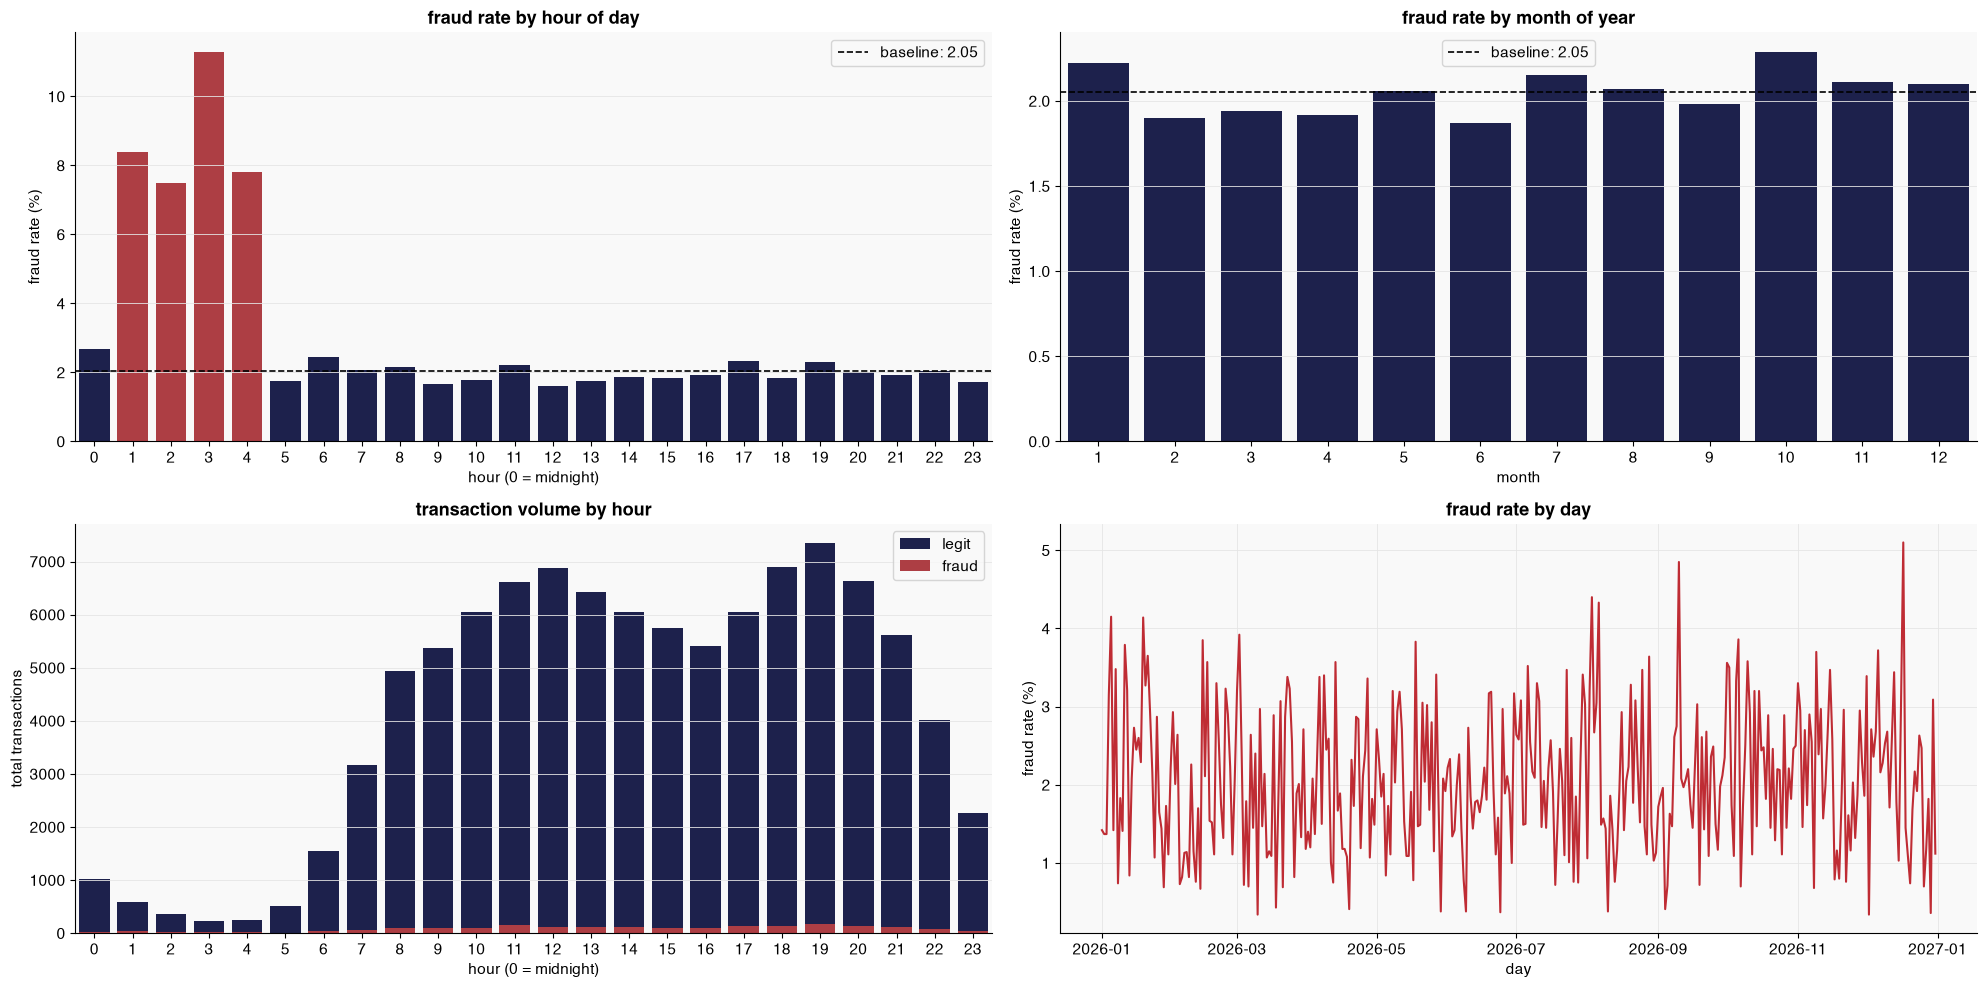

hours with high fraud rates:
 transaction_hour  fraud_rate
                0        2.67
                2        7.48
                4        7.81
                1        8.38
                3       11.30

days with high fraud rates:
transaction_date  fraud_rate
      2026-01-05        4.15
      2026-08-06        4.33
      2026-08-03        4.40
      2026-09-10        4.85
      2026-12-17        5.10


In [14]:
# temporal analysis
fig, ax = plt.subplots(2, 2, figsize=(20, 10))
baseline = (fraud_df["is_fraud"].mean() * 100).round(2)

# % fraud per hour
hourly = fraud_df.groupby("transaction_hour").agg(
    total=("is_fraud", "count"),
    fraud=("is_fraud", "sum")
).reset_index()
hourly["fraud_rate"] = (hourly["fraud"] / hourly["total"] * 100).round(2)

# color massive outliers red
hour_colors = [RED if rate > baseline * 1.5 else BLUE for rate in hourly["fraud_rate"]]

sns.barplot(
    data=hourly,
    x="transaction_hour",
    y="fraud_rate",
    hue="transaction_hour",
    palette=hour_colors,
    ax=ax[0,0],
    legend=False
)

ax[0,0].set_xlabel("hour (0 = midnight)")
ax[0,0].set_ylabel("fraud rate (%)")
ax[0,0].axhline(baseline, color="black", linewidth=1.2, linestyle="--", label=f"baseline: {baseline}")
ax[0,0].legend()
ax[0,0].set_title("fraud rate by hour of day", fontweight="bold")

# % fraud per month
monthly = fraud_df.groupby("transaction_month").agg(
    total=("is_fraud", "count"),
    fraud=("is_fraud", "sum")
).reset_index()
monthly["fraud_rate"] = (monthly["fraud"] / monthly["total"] * 100).round(2)

# color massive outliers red
month_colors = [RED if rate > baseline * 1.5 else BLUE for rate in monthly["fraud_rate"]]

sns.barplot(
    data=monthly,
    x="transaction_month",
    y="fraud_rate",
    hue="transaction_month",
    palette=month_colors,
    ax=ax[0,1],
    legend=False
)

ax[0,1].set_xlabel("month")
ax[0,1].set_ylabel("fraud rate (%)")
ax[0,1].axhline(baseline, color="black", linewidth=1.2, linestyle="--", label=f"baseline: {baseline}")
ax[0,1].legend()
ax[0,1].set_title("fraud rate by month of year", fontweight="bold")

# transaction volume per hour
sns.barplot(
    data=hourly,
    x="transaction_hour",
    y="total",
    color=BLUE,
    ax=ax[1,0],
    label="legit"
)
# total amount of fraud out of total transactions
sns.barplot(
    data=hourly,
    x="transaction_hour",
    y="fraud",
    color=RED,
    ax=ax[1,0],
    label="fraud"
)

ax[1,0].set_xlabel("hour (0 = midnight)")
ax[1,0].set_ylabel("total transactions")
ax[1,0].set_title("transaction volume by hour", fontweight="bold")

# top days for fraud
daily = fraud_df.groupby("transaction_date").agg(
    total = ("is_fraud", "count"),
    fraud = ("is_fraud", "sum")
).reset_index()
daily["fraud_rate"] = (daily["fraud"] / daily["total"] * 100).round(2)

sns.lineplot(
    data=daily,
    x="transaction_date",
    y="fraud_rate",
    markers=True,
    color=RED,
    ax=ax[1,1],
)

ax[1,1].set_xlabel("day")
ax[1,1].set_ylabel("fraud rate (%)")
ax[1,1].set_title("fraud rate by day", fontweight="bold")

plt.tight_layout()
plt.show()

print("hours with high fraud rates:")
print(hourly[["transaction_hour", "fraud_rate"]].sort_values(by="fraud_rate").tail(5).to_string(index=False))
print()
print("days with high fraud rates:")
print(daily[["transaction_date", "fraud_rate"]].sort_values(by="fraud_rate").tail(5).to_string(index=False))

### Temporal Features ###
- Large fraud rate spikes between hours 1 - 4 
- Fraud is pretty general across the year and months; no visible spikes 

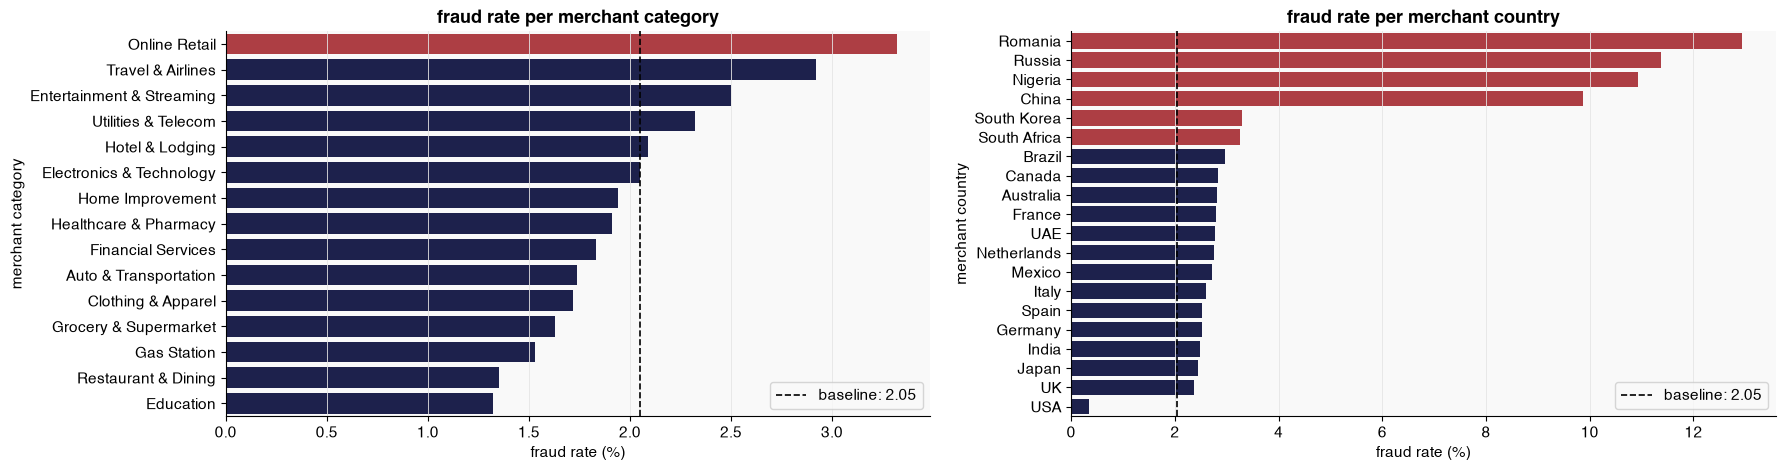

In [15]:
# merchant profile analysis 
fig, ax = plt.subplots(1, 2, figsize=(20, 5))
baseline = (fraud_df["is_fraud"].mean() * 100).round(2)

# % fraud for each merchant category
merchant_cat = fraud_df.groupby("merchant_category").agg(
    fraud = ("is_fraud", "sum"),
    total = ("is_fraud", "count")
).reset_index()
merchant_cat["fraud_rate"] = (merchant_cat["fraud"] / merchant_cat["total"] * 100).round(2)
merchant_cat = merchant_cat.sort_values(by="fraud_rate", ascending=False)

merchant_cat_colors = [RED if rate > baseline * 1.5 else BLUE for rate in merchant_cat["fraud_rate"]]

sns.barplot(
    data=merchant_cat,
    x="fraud_rate",
    y="merchant_category",
    hue="merchant_category",
    ax=ax[0],
    palette=merchant_cat_colors
)

ax[0].set_xlabel("fraud rate (%)")
ax[0].set_ylabel("merchant category")
ax[0].axvline(baseline, color="black", linewidth=1.2, linestyle="--", label=f"baseline: {baseline}")
ax[0].legend()
ax[0].set_title("fraud rate per merchant category", fontweight="bold")

# % fraud for each merchant country
merchant_country = fraud_df.groupby("merchant_country").agg(
    fraud = ("is_fraud", "sum"),
    total = ("is_fraud", "count")
).reset_index()
merchant_country["fraud_rate"] = (merchant_country["fraud"] / merchant_country["total"] * 100).round(2)
merchant_country = merchant_country.sort_values(by="fraud_rate", ascending=False)

merchant_country_colors = [RED if rate > baseline * 1.5 else BLUE for rate in merchant_country["fraud_rate"]]

sns.barplot(
    data=merchant_country,
    x="fraud_rate",
    y="merchant_country",
    hue="merchant_country",
    ax=ax[1],
    palette=merchant_country_colors
)

ax[1].set_xlabel("fraud rate (%)")
ax[1].set_ylabel("merchant country")
ax[1].axvline(baseline, color="black", linewidth=1.2, linestyle="--", label=f"baseline: {baseline}")
ax[1].legend()
ax[1].set_title("fraud rate per merchant country", fontweight="bold")

plt.show()

### Merchant Features ###
- Hotel Lodging + Home Improvement + Online Retail have higher fraud rates
- Romania, Russia, Nigeria, and China all have very high fraud rate baselines compared to every other merchant country. Going well past the 1.01% baseline all >4%.

In [16]:
fraud_df["account_age_days"]

0         709
1        1143
2         601
3         582
4         711
         ... 
99995      19
99996      49
99997     639
99998      89
99999     110
Name: account_age_days, Length: 100000, dtype: int64

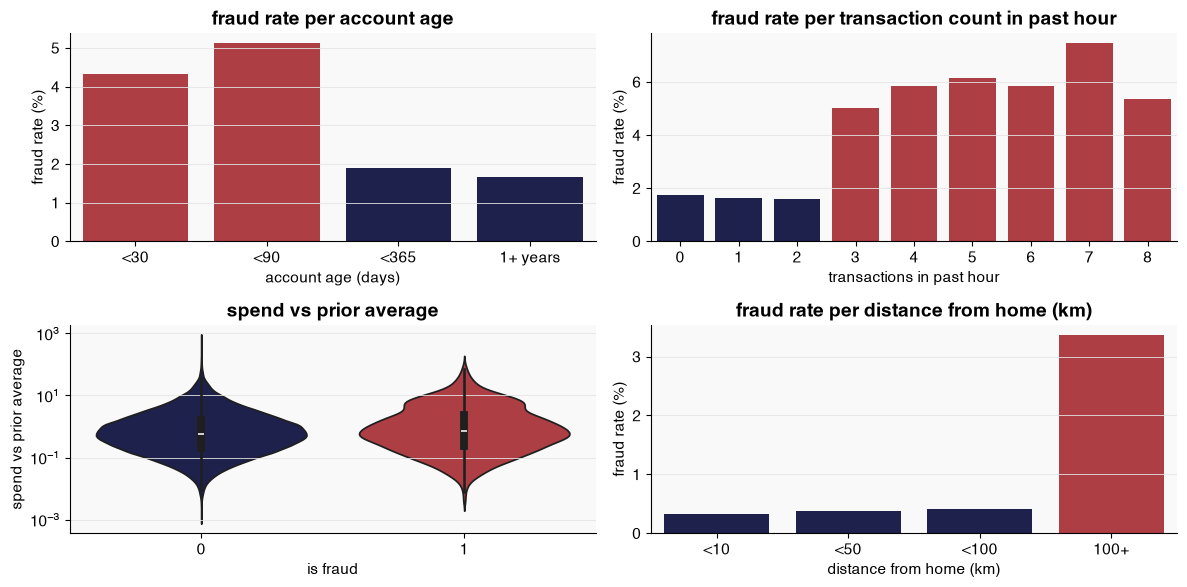

In [17]:
# customer analysis
fig, ax = plt.subplots(2, 2, figsize=(12,6))

# fraud rate by account age
edges = [-1, 30, 90, 365, np.inf]
groups = ["<30", "<90", "<365", "1+ years"]
fraud_df["account_age_bins"] = pd.cut(fraud_df["account_age_days"], bins=edges, labels=groups)

account_age = fraud_df.groupby("account_age_bins").agg(
    fraud = ("is_fraud", "sum"),
    total = ("is_fraud", "count")
).reset_index()
account_age["fraud_rate"] = (account_age["fraud"] / account_age["total"] * 100).round(2)

sns.barplot(
    data=account_age, 
    x="account_age_bins", 
    y="fraud_rate", 
    hue="account_age_bins",
    palette=[RED, RED, BLUE, BLUE],
    dodge=False,
    legend=False,
    ax=ax[0,0]
)

ax[0,0].set_title("fraud rate per account age", fontsize=14, fontweight="bold")
ax[0,0].set_xlabel("account age (days)")
ax[0,0].set_ylabel("fraud rate (%)")

# fraud rate by transaction count
transactions_past_hour = fraud_df.groupby("transactions_last_1h").agg(
    fraud = ("is_fraud", "sum"),
    total = ("is_fraud", "count")
).reset_index()
transactions_past_hour["fraud_rate"] = (transactions_past_hour["fraud"] / transactions_past_hour["total"] * 100).round(2)

sns.barplot(
    data=transactions_past_hour,
    x="transactions_last_1h",
    y="fraud_rate",
    hue="transactions_last_1h",
    palette=[BLUE, BLUE, BLUE, RED, RED, RED, RED, RED, RED],
    dodge=False,
    legend=False,
    ax=ax[0,1]
)

ax[0,1].set_title("fraud rate per transaction count in past hour", fontsize=14, fontweight="bold")
ax[0,1].set_xlabel("transactions in past hour")
ax[0,1].set_ylabel("fraud rate (%)")

# fraud rate by spend vs prior average
sns.violinplot(
    data=fraud_df,
    x="is_fraud",
    y="amount_vs_avg_ratio",
    hue="is_fraud",
    palette=[BLUE, RED],
    log_scale=True,
    legend=False,
    ax=ax[1,0]
)

ax[1,0].set_title("spend vs prior average", fontsize=14, fontweight="bold")
ax[1,0].set_xlabel("is fraud")
ax[1,0].set_ylabel("spend vs prior average")

# fraud rate by distance from home
edges = [-1, 10, 50, 100, np.inf]
groups = ["<10", "<50", "<100", "100+"]
fraud_df["distance_from_home_km_bins"] = pd.cut(fraud_df["distance_from_home_km"], bins=edges, labels=groups)

distance_from_home = fraud_df.groupby("distance_from_home_km_bins").agg(
    fraud = ("is_fraud", "sum"),
    total = ("is_fraud", "count")
).reset_index()
distance_from_home["fraud_rate"] = (distance_from_home["fraud"] / distance_from_home["total"] * 100).round(2)

sns.barplot(
    data=distance_from_home, 
    x="distance_from_home_km_bins", 
    y="fraud_rate", 
    hue="distance_from_home_km_bins",
    palette=[BLUE, BLUE, BLUE, RED],
    dodge=False,
    legend=False,
    ax=ax[1,1]
)

ax[1,1].set_title("fraud rate per distance from home (km)", fontsize=14, fontweight="bold")
ax[1,1].set_xlabel("distance from home (km)")
ax[1,1].set_ylabel("fraud rate (%)")

plt.tight_layout()
plt.show()

### Account-Holder Features ###
- Accounts younger than 90 days have a higher rate of fraud (>2%)
- Transactions above three in the past hour also show higher fraud rates (2-3%). Large amount of transactions tend to be a good velocity feature in flagging fraud
- Transactions over 100+ km tend spike the fraud rate >1.5% 

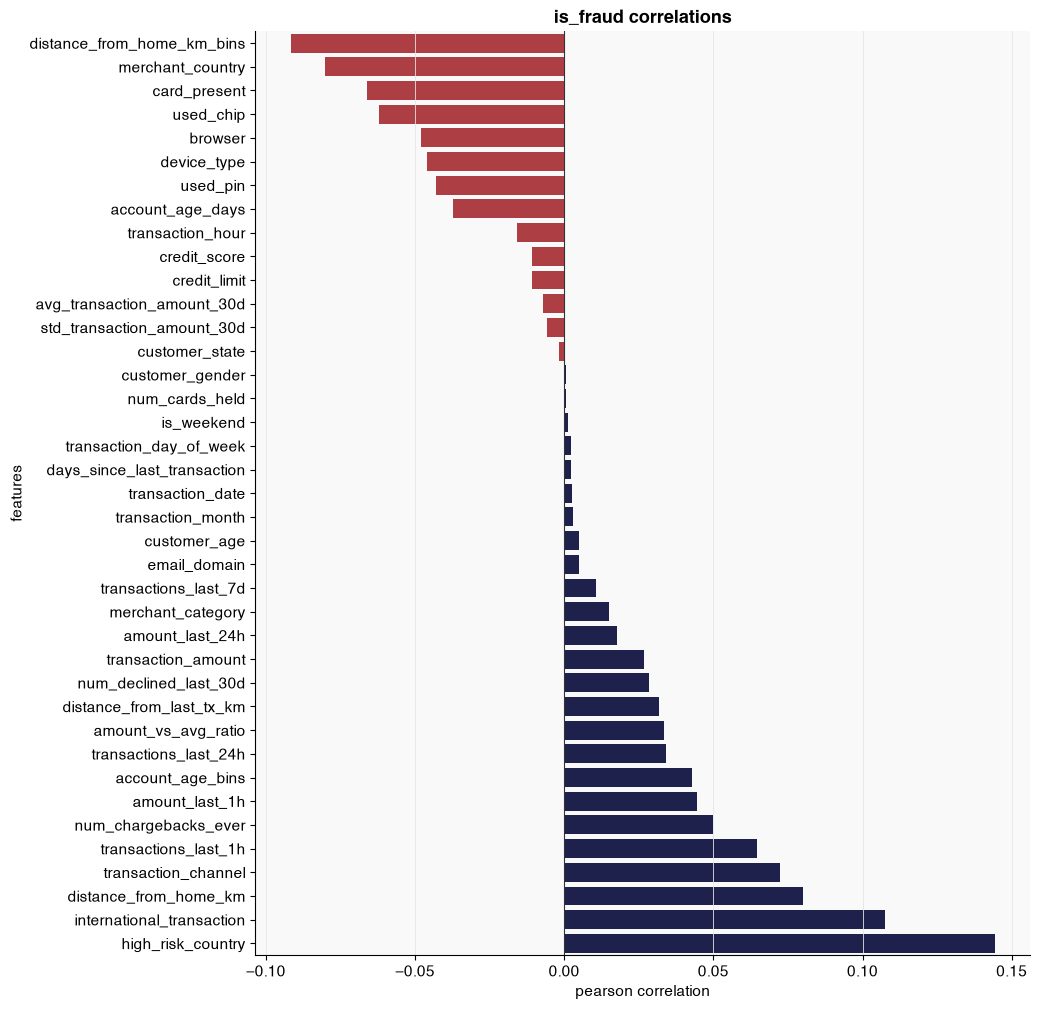

top 10 positive correlations with fraud:
amount_vs_avg_ratio          0.03
transactions_last_24h        0.03
account_age_bins             0.04
amount_last_1h               0.04
num_chargebacks_ever         0.05
transactions_last_1h         0.06
transaction_channel          0.07
distance_from_home_km        0.08
international_transaction    0.11
high_risk_country            0.14

top 10 negative correlations with fraud:
distance_from_home_km_bins   -0.09
merchant_country             -0.08
card_present                 -0.07
used_chip                    -0.06
browser                      -0.05
device_type                  -0.05
used_pin                     -0.04
account_age_days             -0.04
transaction_hour             -0.02
credit_score                 -0.01


In [18]:
# correlation plot
ids = ["transaction_id", "customer_id", "merchant_id", "card_id", "transaction_datetime"]
targets = ["fraud_type", "fraud_amount_lost"]

copy = fraud_df.drop(ids + targets, axis=1).copy()
for col in copy.columns:
    copy[col] = LabelEncoder().fit_transform(copy[col]) 

# get pearson coef for each feature
fraud_corr = copy.corr(numeric_only=True)["is_fraud"]
fraud_corr = fraud_corr.drop("is_fraud")
fraud_corr = fraud_corr.sort_values(ascending=True)

# negative coef = red, positive coef = blue
colors = [RED if corr < 0 else BLUE for corr in fraud_corr.values]

plt.figure(figsize=(10, 12))
sns.barplot(
    x=fraud_corr.values,
    y=fraud_corr.index,
    hue=fraud_corr.index,
    palette=colors,
    legend=False
)
plt.xlabel("pearson correlation")
plt.ylabel("features")
plt.axvline(0, color="#333", linewidth=0.8)
plt.title("is_fraud correlations", fontweight="bold")
plt.show()

print("top 10 positive correlations with fraud:")
print(fraud_corr.tail(10).round(2).to_string())
print()
print("top 10 negative correlations with fraud:")
print(fraud_corr.head(10).round(2).to_string())

Features that convey far distances from the account-holders home are major predictors, with velocity features such as chargebacks, and transactions in a certain time period also having higher correlations. 

In [19]:
# cleaning
fraud_df["browser"] = fraud_df["browser"].fillna("Unknown")
# sort df for temporal split
fraud_df = fraud_df.sort_values(by="transaction_datetime", ascending=True)

### Feature Engineering ###

In [20]:
# hours from 1-4 have higher fraud rates
fraud_df["is_night"] = fraud_df["transaction_hour"].isin([1, 2, 3, 4]).astype(int)

# transactions 3+ within the last hour have higher fraud rates
fraud_df["frequent_transactions_past_1h"] = (fraud_df["transactions_last_1h"] >= 3).astype(int)

# transaction far from home
fraud_df["is_far"] = (fraud_df["distance_from_home_km"] > 100).astype(int)

fraud_df["high_chargeback_amount"] = (fraud_df["num_chargebacks_ever"] > 2).astype(int)

# if far and days since last transaction small, then suspicous
fraud_df["distance_and_days_since_last_tx"]= (fraud_df["distance_from_last_tx_km"] / fraud_df["days_since_last_transaction"]).round(2)

# account is new <90 days
fraud_df["new_account"] = (fraud_df["account_age_days"] < 90).astype(int)

# transaction is online & retail + high risk country
fraud_df["suspicous_purchase"] = ((fraud_df["merchant_category"] == "Online Retail") & (fraud_df["merchant_country"].isin(["Romania", "Russia", "Nigeria", "China"]))).astype(int)

fraud_df["amount_last_1h_24h_ratio"] = (fraud_df["amount_last_1h"] / fraud_df["amount_last_24h"]).round(2)

# transaction amount 30d zscore
fraud_df["transaction_30d_zscore"] = ((fraud_df["transaction_amount"] - fraud_df["avg_transaction_amount_30d"]) / fraud_df["std_transaction_amount_30d"]).round(2)

fraud_df["high_30d_zscore"] = (fraud_df["transaction_30d_zscore"] > 6).astype(int)

fraud_df["fraud_suspicous_score"] = (
    fraud_df["is_night"] * 4 +
    fraud_df["frequent_transactions_past_1h"] * 2.5 +
    fraud_df["is_far"] * 1.5 +
    fraud_df["high_chargeback_amount"] * 3 +
    fraud_df["new_account"] * 3 +
    fraud_df["suspicous_purchase"] * 6 +
    fraud_df["high_30d_zscore"] * 3 + 
    fraud_df["high_risk_country"] * 10
)

display(fraud_df)

,transaction_id,customer_id,card_id,merchant_id,transaction_datetime,transaction_amount,merchant_category,merchant_country,transaction_hour,transaction_day_of_week,card_present,customer_age,customer_gender,customer_state,account_age_days,credit_limit,credit_score,num_cards_held,transactions_last_1h,transactions_last_24h,transactions_last_7d,amount_last_1h,amount_last_24h,days_since_last_transaction,distance_from_home_km,distance_from_last_tx_km,international_transaction,high_risk_country,amount_vs_avg_ratio,used_chip,used_pin,transaction_channel,device_type,browser,is_weekend,avg_transaction_amount_30d,std_transaction_amount_30d,num_declined_last_30d,num_chargebacks_ever,email_domain,is_fraud,fraud_type,fraud_amount_lost,transaction_month,transaction_date,account_age_bins,distance_from_home_km_bins,is_night,frequent_transactions_past_1h,is_far,high_chargeback_amount,distance_and_days_since_last_tx,new_account,suspicous_purchase,amount_last_1h_24h_ratio,transaction_30d_zscore,high_30d_zscore,fraud_suspicous_score
0,TXN-00000001,CUS-00006042,CRD-00006042,MER-00002507,2026-01-01 02:28:51,37.36,Healthcare & Pharmacy,USA,2,Monday,0,41,Female,PA,709,6630.0,742,2,1,2,3,88.91,209.94,0.9,13.0,0.3,0,0,0.398,0,0,Online,Mobile,Chrome,0,93.91,39.48,0,0,corporate,0,Legitimate,0.00,1,2026-01-01,1+ years,<50,1,0,0,0,0.33,0,0,0.42,-1.43,0,4.0
1,TXN-00000002,CUS-00005262,CRD-00005262,MER-00000189,2026-01-01 03:15:18,50.04,Restaurant & Dining,Germany,3,Monday,1,56,Male,WV,1143,4350.0,602,1,6,6,23,1290.10,1093.31,6.6,5311.8,17.0,1,0,0.278,1,1,In-store,POS Terminal,Unknown,0,180.05,134.45,0,0,yahoo,0,Legitimate,0.00,1,2026-01-01,1+ years,100+,1,1,1,0,2.58,0,0,1.18,-0.97,0,8.0
2,TXN-00000003,CUS-00005901,CRD-00005901,MER-00002054,2026-01-01 03:44:38,38.87,Grocery & Supermarket,Australia,3,Monday,0,43,Male,MN,601,3950.0,605,4,1,1,3,36.27,46.54,4.2,14164.5,53.2,1,0,0.925,0,0,Online,Desktop,Chrome,0,42.00,22.46,0,0,hotmail,0,Legitimate,0.00,1,2026-01-01,1+ years,100+,1,0,1,0,12.67,0,0,0.78,-0.14,0,5.5
3,TXN-00000004,CUS-00006958,CRD-00006958,MER-00000310,2026-01-01 03:53:41,46.60,Gas Station,China,3,Monday,0,51,Female,OH,582,13870.0,675,5,0,2,3,0.00,134.35,3.0,1119.1,3.6,1,1,0.718,0,1,ATM,ATM,Unknown,0,64.87,29.76,0,0,gmail,0,Legitimate,0.00,1,2026-01-01,1+ years,100+,1,0,1,0,1.20,0,0,0.00,-0.61,0,15.5
4,TXN-00000005,CUS-00003543,CRD-00003543,MER-00001197,2026-01-01 04:29:08,62.13,Clothing & Apparel,UK,4,Monday,1,40,Female,PA,711,6570.0,743,2,1,2,2,38.37,117.74,0.9,6564.5,22.4,1,0,1.317,1,0,In-store,POS Terminal,Unknown,0,47.19,18.52,0,0,gmail,0,Legitimate,0.00,1,2026-01-01,1+ years,100+,1,0,1,0,24.89,0,0,0.33,0.81,0,5.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,TXN-00099996,CUS-00006390,CRD-00006390,MER-00000996,2026-12-31 23:21:36,32.83,Restaurant & Dining,Italy,23,Tuesday,1,48,Female,FL,19,8490.0,588,3,0,1,7,0.00,88.90,4.8,11870.8,2.3,1,0,0.340,1,0,In-store,POS Terminal,Unknown,0,96.52,44.55,0,0,gmail,0,Legitimate,0.00,12,2026-12-31,<30,100+,0,0,1,0,0.48,1,0,0.00,-1.43,0,4.5
99996,TXN-00099997,CUS-00006126,CRD-00006126,MER-00001056,2026-12-31 23:26:09,167.72,Electronics & Technology,Spain,23,Tuesday,0,20,Female,UT,49,2750.0,479,5,0,1,19,0.00,75.38,13.1,3630.8,0.2,1,0,2.214,0,1,ATM,ATM,Unknown,0,75.74,41.67,0,2,gmail,0,Legitimate,0.00,12,2026-12-31,<90,100+,0,0,1,0,0.02,1,0,0.00,2.21,0,4.5
99997,TXN-00099998,CUS-00004651,CRD-00004651,MER-00002493,2026-12-31 23:30:16,1031.10,Travel & Airlines,France,23,Tuesday,0,28,Female,NM,639,11630.0,712,2,3,4,7,148.76,194.29,2.4,13186.0,1.4,1,0,22.711,0,0,Mobile App,Mobile,App,0,45.40,35.11,2,4,gmail,1,Card-Not-Present,1012.06,12,2026-12-31,1+ years,100+,0,1,1,1,0.58,0,0,0.77,28.07,1,10.0
99998,TXN-00099999,CUS-00007845,CRD-00007845,MER-00002563,2026-12-31 23:31:19,81.75,Clothing & Apparel,UK,23,Tuesday,0,56,Male,NE,

Engineered richer features that could possibly help the model. I created features based on what signals I noticed were correlated with higher rates of fraud. 

### Model ###
- Want to prioritize F1 score as fraud intervention needs to balance recall and precision so that not every case is labeled fraud (don't want to overpredict on transactions), and so that every case that is predicted is truly fraud (so that business units don't get overwhelmed with cases).

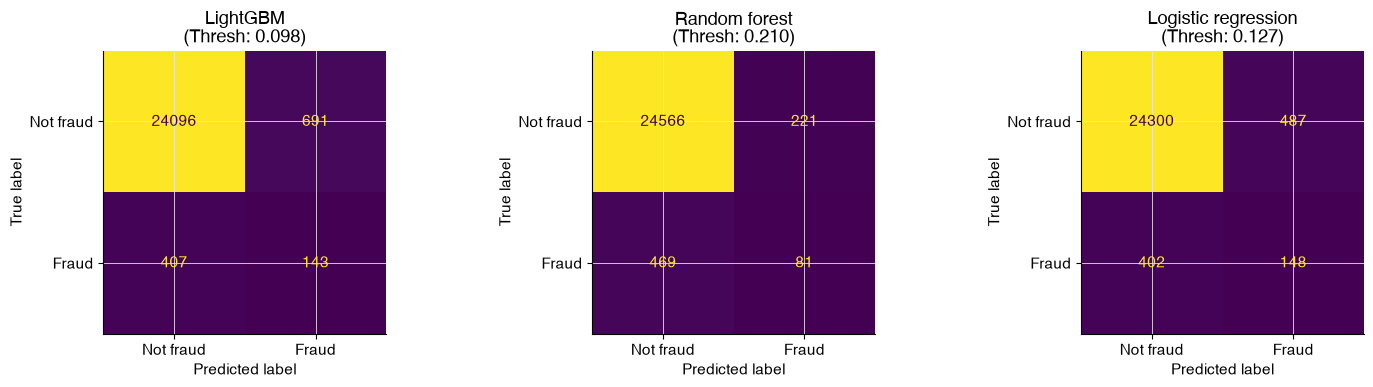

                     threshold  precision  recall      f1  auc_roc
model                                                             
LightGBM                0.0982     0.1715  0.2600  0.2066   0.8405
Random forest           0.2100     0.2682  0.1473  0.1901   0.8292
Logistic regression     0.1271     0.2331  0.2691  0.2498   0.8536


In [21]:
from lightgbm import LGBMClassifier
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def find_best_threshold(y_true, y_probs):
    """Finds the probability threshold that maximizes the F1 score."""
    precisions, recalls, thresholds = precision_recall_curve(y_true, y_probs)
    f1_scores = (
        2
        * (precisions[:-1] * recalls[:-1])
        / (precisions[:-1] + recalls[:-1] + 1e-10)
    )
    best_idx = np.argmax(f1_scores)
    return thresholds[best_idx]


# parse the timestamp for splitting
# it will not be used as a model feature
data = fraud_df.copy()
data["transaction_datetime"] = pd.to_datetime(
    data["transaction_datetime"], errors="coerce"
)
data = data.dropna(subset=["transaction_datetime", "is_fraud"]).copy()

years = data["transaction_datetime"].dt.year.unique()
if len(years) != 1:
    raise ValueError(
        "Expected one calendar year for the Jan-Sep/Oct-Dec split; "
        f"found {sorted(years)}. Filter to the intended year first."
    )

train_mask = data["transaction_datetime"].dt.month.between(1, 9)
test_mask = data["transaction_datetime"].dt.month.between(10, 12)

drop_cols = [
    "transaction_id",
    "customer_id",
    "card_id",
    "merchant_id",
    "transaction_datetime",
    "transaction_day_of_week",
    "customer_gender",
    "customer_state",
    "num_cards_held",
    "is_weekend",
    "transaction_date",
    "transaction_month",
    "fraud_type",
    "is_fraud",
    "fraud_amount_lost",
]

X = data.drop(columns=drop_cols, errors="ignore")
X = X.replace([np.inf, -np.inf], np.nan)
y = data["is_fraud"].astype(int)

X_train, X_test = X.loc[train_mask], X.loc[test_mask]
y_train, y_test = y.loc[train_mask], y.loc[test_mask]

if X_train.empty or X_test.empty:
    raise ValueError(
        "The temporal split produced an empty train or test set; check the"
        " transaction dates."
    )

# create a temporal validation split inside Jan-Sep training data
train_months = data.loc[train_mask, "transaction_datetime"].dt.month
sub_train_mask = train_months.between(1, 7)  # Jan - Jul
val_mask = train_months.between(8, 9)  # Aug - Sep

X_sub_train, y_sub_train = (
    X_train.loc[sub_train_mask],
    y_train.loc[sub_train_mask],
)
X_val, y_val = X_train.loc[val_mask], y_train.loc[val_mask]

# detect categorical columns from their pandas dtypes
categorical_cols = X_train.select_dtypes(
    include=["object", "category", "string", "bool"]
).columns.tolist()
numeric_cols = X_train.select_dtypes(include=["number"]).columns.tolist()

models = {
    "LightGBM": LGBMClassifier(random_state=42, verbosity=-1),
    "Random forest": RandomForestClassifier(
        n_estimators=300, random_state=42, n_jobs=-1
    ),
    "Logistic regression": LogisticRegression(max_iter=2000, random_state=42),
}

results = []
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for (name, model), ax in zip(models.items(), axes):
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if name == "Logistic regression":
        numeric_steps.append(("scaler", StandardScaler()))

    numeric_pipeline = Pipeline(numeric_steps)
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "encoder",
            OneHotEncoder(),
        ),
    ])

    preprocess = ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_cols),
        ("categorical", categorical_pipeline, categorical_cols),
    ])

    pipeline = Pipeline([
        ("preprocess", preprocess),
        ("model", model),
    ])

    # 1. fit on Jan-Jul and find the optimal threshold on Aug-Sep
    pipeline.fit(X_sub_train, y_sub_train)
    val_probs = pipeline.predict_proba(X_val)[:, 1]
    best_thresh = find_best_threshold(y_val, val_probs)

    # 2. retrain on the full Jan-Sep training set before final evaluation
    pipeline.fit(X_train, y_train)
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    # 3. apply the tuned threshold instead of the default 0.5
    predictions = (probabilities >= best_thresh).astype(int)

    results.append({
        "model": name,
        "threshold": best_thresh,
        "precision": precision_score(y_test, predictions, zero_division=0),
        "recall": recall_score(y_test, predictions, zero_division=0),
        "f1": f1_score(y_test, predictions, zero_division=0),
        "auc_roc": (
            roc_auc_score(y_test, probabilities)
            if y_test.nunique() == 2
            else np.nan
        ),
    })

    cm = confusion_matrix(y_test, predictions, labels=[0, 1])
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Not fraud", "Fraud"],
    ).plot(ax=ax, colorbar=False)
    ax.set_title(f"{name}\n(Thresh: {best_thresh:.3f})")

plt.tight_layout()
plt.show()

metrics_df = pd.DataFrame(results).set_index("model")
print(metrics_df.round(4))

### Oversampling ###
- Going to try oversampling to hopefully help out and deal with some of the class imbalance.

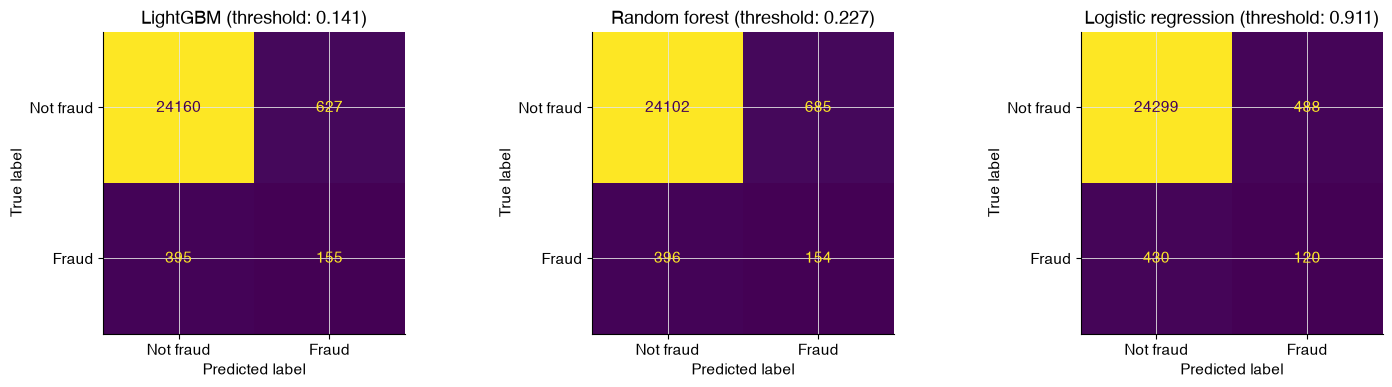

With Oversampling:
                     threshold  precision  recall      f1  auc_roc
model                                                             
LightGBM                0.1413     0.1982  0.2818  0.2327   0.8369
Random forest           0.2267     0.1836  0.2800  0.2217   0.8293
Logistic regression     0.9110     0.1974  0.2182  0.2073   0.8311


In [22]:
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.base import clone

minority_count = int(y_sub_train.value_counts().min())
if minority_count < 2:
    raise ValueError("SMOTENC needs at least two minority examples in Jan-Jul.")

k_neighbors = min(5, minority_count - 1)

smotenc_results = []
fig, axes = plt.subplots(1, len(models), figsize=(5 * len(models), 4))

for (name, estimator), ax in zip(models.items(), axes):
    # impute before SMOTENC
    # fit only on the current training partition.
    impute_for_smote = ColumnTransformer(
        [
            ("numeric", SimpleImputer(strategy="median", keep_empty_features=True), numeric_cols),
            ("categorical", SimpleImputer(strategy="most_frequent", keep_empty_features=True), categorical_cols),
        ],
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")

    numeric_preprocess = (
        Pipeline([("scaler", StandardScaler())])
        if name == "Logistic regression"
        else "passthrough"
    )
    preprocess = ColumnTransformer(
        [
            ("numeric", numeric_preprocess, numeric_cols),
            ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ]
    )

    pipeline = ImbPipeline(
        [
            ("impute_for_smote", impute_for_smote),
            (
                "oversample",
                SMOTENC(
                    categorical_features=categorical_cols,
                    k_neighbors=k_neighbors,
                    random_state=42,
                ),
            ),
            ("preprocess", preprocess),
            ("model", clone(estimator)),
        ]
    )

    # tune the threshold on the original, unresampled validation period.
    pipeline.fit(X_sub_train, y_sub_train)
    val_probabilities = pipeline.predict_proba(X_val)[:, 1]
    threshold = find_best_threshold(y_val, val_probabilities)

    # refit on Jan-Sep
    # SMOTENC resamples only this training data.
    pipeline.fit(X_train, y_train)
    probabilities = pipeline.predict_proba(X_test)[:, 1]
    predictions = (probabilities >= threshold).astype(int)

    smotenc_results.append({
        "model": name,
        "threshold": threshold,
        "precision": precision_score(y_test, predictions, zero_division=0),
        "recall": recall_score(y_test, predictions, zero_division=0),
        "f1": f1_score(y_test, predictions, zero_division=0),
        "auc_roc": (
            roc_auc_score(y_test, probabilities)
            if y_test.nunique() == 2
            else np.nan
        ),
    })

    cm = confusion_matrix(y_test, predictions, labels=[0, 1])
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Not fraud", "Fraud"],
    ).plot(ax=ax, colorbar=False, values_format="d")
    ax.set_title(f"{name} (threshold: {threshold:.3f})")

plt.tight_layout()
plt.show()

smotenc_metrics_df = pd.DataFrame(smotenc_results).set_index("model")
print("With Oversampling:")
print(smotenc_metrics_df.round(4))